In [4]:
import re
import os
import pandas as pd
import numpy as np
from Bio import SeqIO
from datetime import datetime
from plotnine import *
import geopandas as gpd

In [5]:
# Upload metadata

In [68]:
FILE = "./BEAST/empirical_trees/submission_files/2026-01_main-intro_equal-time-loc_ha_empirical_targetedbeast/div-tree-metadata.tsv"
# FILE = "./BEAST/empirical_trees/submission_files/2026-01_main-intro_equal-time-host-1000_ha_empirical_targetedbeast/div-tree-metadata.tsv"
# FILE = "./BEAST/empirical_trees/submission_files/2026-01_main-intro_equal-time-host-3000_ha_empirical_targetedbeast/div-tree-metadata.tsv"

In [69]:
metadata = pd.read_csv(FILE, sep = "\t")

In [70]:
print(len(metadata))

4347


In [59]:
# Make a year_month column and group by it

In [60]:
metadata["year_month"] = metadata["ncbibvbrc_date"].str.split("-", expand = True)[0] + "_" + metadata["ncbibvbrc_date"].str.split("-", expand = True)[1]

In [61]:
metadata_grouped = metadata.groupby("year_month")

In [62]:
# Plot 

In [63]:
# Some plotting edits: 

# order the division by most to least 
order = (metadata["ncbibvbrc_division"].value_counts().index)
metadata_divisionordered = metadata.copy()

metadata_divisionordered["ncbibvbrc_division"] = pd.Categorical(metadata_divisionordered["ncbibvbrc_division"], categories=order, ordered=True)

# Make sure "other" and "other " are the same in the hostgroup column
metadata["ncbibvbrc_hostgroup"] = metadata["ncbibvbrc_hostgroup"].str.strip()

In [64]:
host_group_colors = {"bird-of-prey":"#C43110", # red-maroon
                     "duck":"#679C48", # green 
                     "goose-swan": "#DBB730", # yellow
                     "shorebird":"#68A0A6", # blue
                     "songbird-etc":"#D9A7B0", # pink
                     "ground-bird":"#E08907", # orange
                     "diving-bird":"#503A63", # deep purple
                     "other":"#A0A0A3" # grey
                    }

flyway_colors = {"AtlanticFlyway":"#AA7722", "MississippiFlyway":"#5E9B82", "CentralFlyway":"#C593D1", "PacificFlyway":"#2B57B3", "unknown":"#9C9C9C"}

country_colors = {"USA":"#5E9B82", "Canada":"#C593D1", "Mexico":"#2B57B3"}

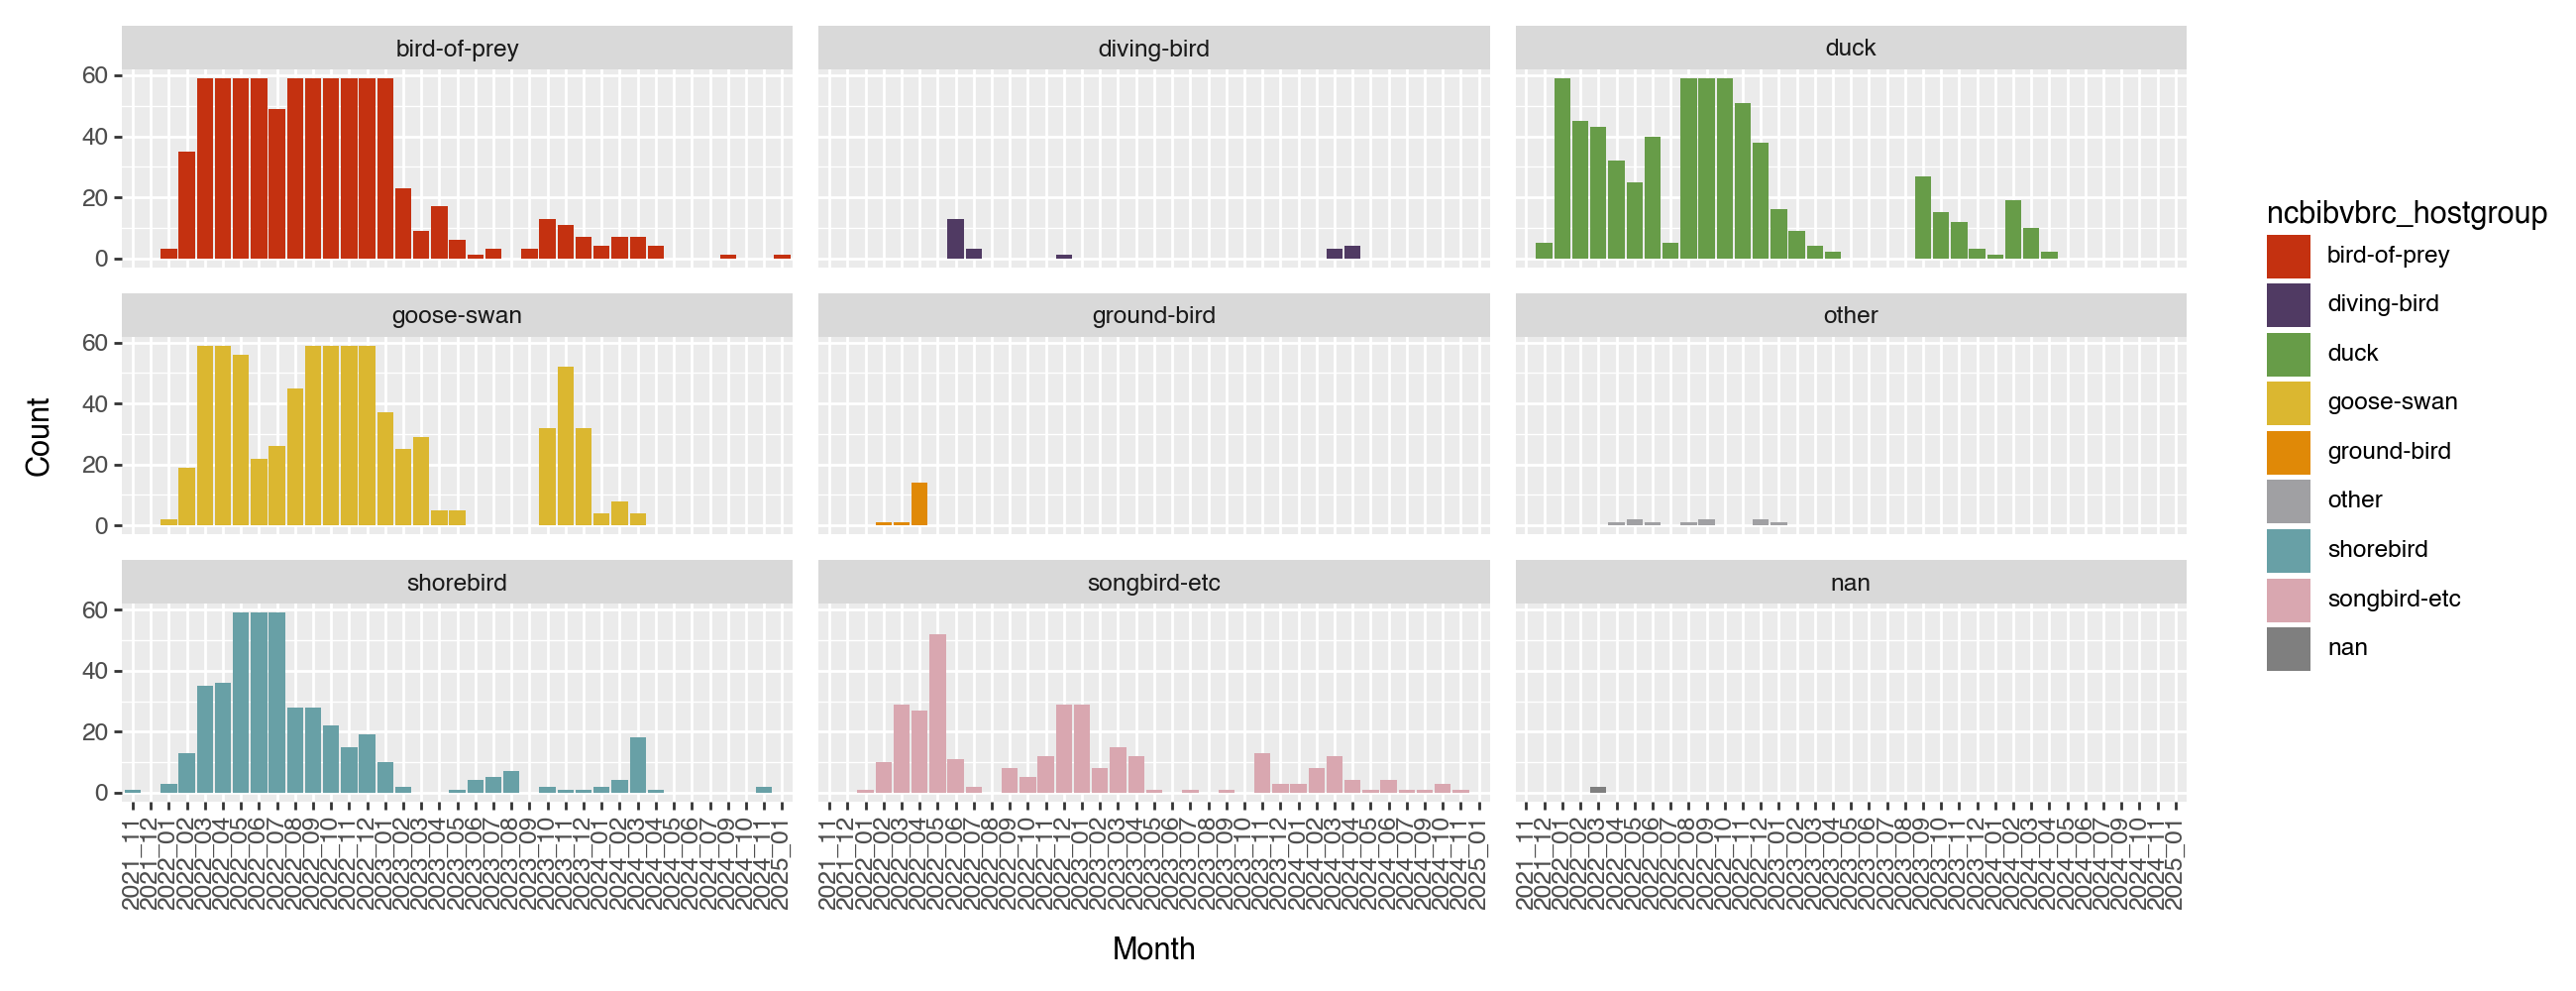

In [65]:
equal_dataset_plot = (
    # ggplot(metadata, aes(x = "year_month", fill = "ncbibvbrc_flyway"))
    # ggplot(metadata_divisionordered, aes(x = "ncbibvbrc_division"))
    ggplot(metadata, aes(x = "year_month", fill = "ncbibvbrc_hostgroup"))
    + geom_bar(stat = "count")#, fill = "#5E9B82")
    # + scale_fill_manual(flyway_colors)
    + scale_fill_manual(host_group_colors)
    + facet_wrap("ncbibvbrc_hostgroup")
    + labs(x = "Month", y = "Count")
    + theme(figure_size = (13, 5), axis_text_x = element_text(rotation = 90))
) 

equal_dataset_plot.show()

In [66]:
equal_dataset_plot.save(filename = './metadata/exploratory_data_analysis/equal-time-host-3000.png', height=10, width=20, units = 'in', dpi=750)

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./metadata/exploratory_data_analysis/equal-time-host-3000.png
